# Run 1 · Test (data-discovery)
Tests what Sarah Okafor said in discovery (`../notes/interview.md`) against this run's data. Every number comes from a code cell.
**Defaults unless stated** (from `RUN.md`): SSP245, 2050, all four hazards, each property counted once for £ loss. Only one choice is changed at a time.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('../data/spectra_portfolio_export.csv')
H = ['flood','subsidence','heat','wind']; S = ['ssp126','ssp245','ssp585']; Y = ['2030','2050']
u = df.drop_duplicates('property_id')   # one row per property, for £ loss
def loss(scen='ssp245', yr='2050', hazards=H, frame=u):
    return frame[[f'{h}_{scen}_{yr}_loss_gbp' for h in hazards]].sum(axis=1, min_count=1).sum()
print(len(df), 'loans |', len(u), 'properties |', df.shape[1], 'columns')

2000 loans | 1880 properties | 81 columns


## 1. Claims from the interview
All from Sarah (role-played customer).

In [2]:
claims = pd.DataFrame([
 ['C1','About 15 questions a month; each takes 2–5 days; "roughly 45 analyst days a month"','Volume'],
 ['C2','Filtering takes about an hour; most time goes on deciding scenario, horizon and loan population, then the write-up','Workflow'],
 ['C3','"One subtly wrong scenario choice and the number means something different"','Why she checks'],
 ['C4','Questions are "mostly one-offs"; only the risk committee pack (hazard × region × scenario) repeats','Repeats'],
 ['C5','Answers trigger follow-ups ("what about the severe scenario?", which hazard, which region)','Follow-ups'],
 ['C6','She checks that "the right loans are in or out" and that "totals reconcile back to the book"','Checks'],
 ['C7','Analysts wrestle "with a spreadsheet of hundreds of columns"','Data shape'],
 ['C8','Joining to internal loan data on loan ID "usually lines up"','Data join'],
 ['C9','Model risk will only approve if "every number is computed by code and traceable back to the data"','Trust (requirement)'],
], columns=['id','claim','topic']); claims

,id,claim,topic
0,C1,About 15 questions a month; each takes 2–5 day...,Volume
1,C2,Filtering takes about an hour; most time goes ...,Workflow
2,C3,"""One subtly wrong scenario choice and the numb...",Why she checks
3,C4,"Questions are ""mostly one-offs""; only the risk...",Repeats
4,C5,"Answers trigger follow-ups (""what about the se...",Follow-ups
5,C6,"She checks that ""the right loans are in or out...",Checks
6,C7,"Analysts wrestle ""with a spreadsheet of hundre...",Data shape
7,C8,"Joining to internal loan data on loan ID ""usua...",Data join
8,C9,"Model risk will only approve if ""every number ...",Trust (requirement)


## 2. Tests

In [3]:
# C1: arithmetic of the baseline
lo, hi = 15*2, 15*5
print(f'15 requests x 2-5 days = {lo}-{hi} analyst days a month; "45" implies an average of {45/15:.1f} days per request')
print('Not testable against this file: no request log. Status: UNCLEAR (her estimate; range is wide)')

15 requests x 2-5 days = 30-75 analyst days a month; "45" implies an average of 3.0 days per request
Not testable against this file: no request log. Status: UNCLEAR (her estimate; range is wide)


In [4]:
# C2 + C3: her own credit committee question, changing ONE choice at a time
# "How many CRE loans have a flood rating of E or worse by 2050?"
cre = df[df.loan_type=='Commercial real estate']
def n_e_plus(scen='ssp245', yr='2050', frame=cre):
    return int((frame[f'flood_{scen}_{yr}_rating'] >= 'E').sum())
rows = [['scenario', s, n_e_plus(scen=s)] for s in S] + [['year (SSP245)', y, n_e_plus(yr=y)] for y in Y]
cre_u = cre.drop_duplicates('property_id')
rows += [['count loans vs properties (SSP245 2050)', 'loans', n_e_plus()], ['count loans vs properties (SSP245 2050)', 'properties', n_e_plus(frame=cre_u)]]
q = pd.DataFrame(rows, columns=['choice changed','value','CRE flood E or worse'])
bal = {s: cre.loc[cre[f'flood_{s}_2050_rating']>='E','balance_gbp'].sum() for s in S}
print('same question, by balance £:', {k: f'{v:,}' for k,v in bal.items()})
print('CRE loans with flood 2050 unscored:', {s:int(cre[f'flood_{s}_2050_rating'].isna().sum()) for s in S})
q

same question, by balance £: {'ssp126': '7,148,900', 'ssp245': '7,148,900', 'ssp585': '16,981,600'}
CRE loans with flood 2050 unscored: {'ssp126': 1, 'ssp245': 1, 'ssp585': 1}


,choice changed,value,CRE flood E or worse
0,scenario,ssp126,4
1,scenario,ssp245,4
2,scenario,ssp585,8
3,year (SSP245),2030,4
4,year (SSP245),2050,4
5,count loans vs properties (SSP245 2050),loans,4
6,count loans vs properties (SSP245 2050),properties,4


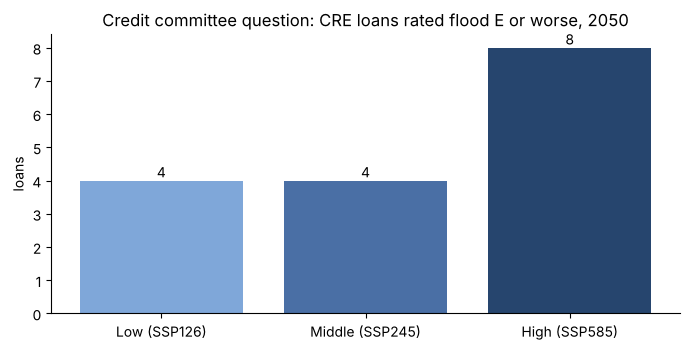

In [5]:
fig, ax = plt.subplots(figsize=(7,3.6))
sub = q[q['choice changed']=='scenario']
ax.bar(['Low (SSP126)','Middle (SSP245)','High (SSP585)'], sub['CRE flood E or worse'], color=['#7fa7d9','#4a6fa5','#26456e'])
for i,v in enumerate(sub['CRE flood E or worse']): ax.text(i, v, str(v), ha='center', va='bottom')
ax.set_title('Credit committee question: CRE loans rated flood E or worse, 2050'); ax.set_ylabel('loans')
ax.spines[['top','right']].set_visible(False); plt.tight_layout(); plt.savefig('test_cre_flood_by_scenario.png', dpi=120); plt.show()

In [6]:
# C3, CRO question: "total expected climate loss by 2050", then "which hazard and region are driving it"
print('Total 2050 by scenario (£):', {s: f'{loss(scen=s):,.0f}' for s in S})
hz = {s: max(H, key=lambda h: loss(scen=s, hazards=[h])) for s in S}
print('top hazard by scenario:', hz)
L = u[[f'{h}_ssp245_2050_loss_gbp' for h in H]].sum(axis=1)
reg = pd.DataFrame({'loss': L.groupby(u.region).sum(), 'value': u.groupby('region').property_value_gbp.sum()})
reg['rate_bp'] = reg.loss/reg.value*1e4
print('top 3 regions by £ (SSP245):', list(reg.loss.sort_values(ascending=False).index[:3]))
print('top 3 regions by loss rate (SSP245):', list(reg.rate_bp.sort_values(ascending=False).index[:3]))
for s in S:
    Ls = u[[f'{h}_{s}_2050_loss_gbp' for h in H]].sum(axis=1)
    print(f'  {s}: top region by £ = {Ls.groupby(u.region).sum().idxmax()}')

Total 2050 by scenario (£): {'ssp126': '2,386,484', 'ssp245': '3,313,709', 'ssp585': '6,099,020'}
top hazard by scenario: {'ssp126': 'subsidence', 'ssp245': 'subsidence', 'ssp585': 'subsidence'}
top 3 regions by £ (SSP245): ['South East', 'London', 'East of England']
top 3 regions by loss rate (SSP245): ['South East', 'London', 'East of England']
  ssp126: top region by £ = South East
  ssp245: top region by £ = South East
  ssp585: top region by £ = South East


In [7]:
# Treasury question: "how much do expected losses rise from 2030 to 2050 under the severe scenario?"
a, b = loss(scen='ssp585', yr='2030'), loss(scen='ssp585', yr='2050')
print(f'SSP585: 2030 £{a:,.0f} -> 2050 £{b:,.0f} = {b/a:.2f}x (+{b/a-1:.1%})')
a2, b2 = loss(scen='ssp245', yr='2030'), loss(scen='ssp245', yr='2050')
print(f'for comparison, SSP245: {b2/a2:.2f}x')
# if "severe" were read as a different scenario, the answer changes:
print('If counted per loan row instead of per property, SSP585 2050 = £%s' % f'{loss(scen="ssp585", frame=df):,.0f}')

SSP585: 2030 £2,222,571 -> 2050 £6,099,020 = 2.74x (+174.4%)
for comparison, SSP245: 1.57x
If counted per loan row instead of per property, SSP585 2050 = £6,226,057


In [8]:
# C4: are the 'one-off' questions structurally the same? Map each to the same few dimensions
qs = pd.DataFrame([
 ['CRO','total expected loss by 2050','sum loss','all','-','2050','(unstated)'],
 ['CRO follow-up','which hazard / region drives it','sum loss','all','hazard, region','2050','(unstated)'],
 ['Credit committee','CRE loans flood E or worse by 2050','count loans','CRE, flood >= E','-','2050','(unstated)'],
 ['Treasury','rise 2030 to 2050, severe','ratio of sums','all','-','2030 vs 2050','severe (SSP585?)'],
 ['Risk committee pack','exposure by hazard, region, scenario','sum','all','hazard, region, scenario','(unstated)','all'],
], columns=['asker','question','metric','filter','group by','year','scenario'])
print('Dimensions used across all five questions: metric, filter (loan type, hazard, rating), group by (hazard, region, scenario), year, scenario')
print('Questions where the scenario was left unstated by the asker:', int(qs.scenario.str.contains('unstated').sum()), 'of', len(qs))
qs

Dimensions used across all five questions: metric, filter (loan type, hazard, rating), group by (hazard, region, scenario), year, scenario
Questions where the scenario was left unstated by the asker: 3 of 5


,asker,question,metric,filter,group by,year,scenario
0,CRO,total expected loss by 2050,sum loss,all,-,2050,(unstated)
1,CRO follow-up,which hazard / region drives it,sum loss,all,"hazard, region",2050,(unstated)
2,Credit committee,CRE loans flood E or worse by 2050,count loans,"CRE, flood >= E",-,2050,(unstated)
3,Treasury,"rise 2030 to 2050, severe",ratio of sums,all,-,2030 vs 2050,severe (SSP585?)
4,Risk committee pack,"exposure by hazard, region, scenario",sum,all,"hazard, region, scenario",(unstated),all


In [9]:
# C6: things she checks that the data shows can go wrong
shared = (df.property_id.value_counts()>1).sum()
print(f'Loans in or out: {shared} properties secure more than one loan; summing loan rows inflates £ loss by {loss(frame=df)/loss()-1:.1%} and counts {len(df)-len(u)} extra properties')
print(f'Unscored: {int(df[[c for c in df.columns if c.endswith("rating")]].isna().any(axis=1).sum())} loans miss at least one hazard-year score')
print('Arrears / status: not in this file -> needs the internal loan data she mentioned')
print(f'Reconcile to book: file balance total £{df.balance_gbp.sum():,}; there is no book total in the file to reconcile against')

Loans in or out: 112 properties secure more than one loan; summing loan rows inflates £ loss by 2.1% and counts 120 extra properties
Unscored: 45 loans miss at least one hazard-year score
Arrears / status: not in this file -> needs the internal loan data she mentioned
Reconcile to book: file balance total £863,339,700; there is no book total in the file to reconcile against


In [10]:
# C7 and C8: data shape and join
print('columns in this export:', df.shape[1], '(risk columns:', sum(c.endswith(('rating','damage_pct','loss_gbp')) for c in df.columns), ')')
print('loan_id unique:', df.loan_id.is_unique, '| loan_id format consistent:', bool(df.loan_id.str.fullmatch(r'L\d{6}').all()))
pc = df.postcode; print('postcodes not in standard format:', int((~pc.str.fullmatch(r'[A-Z]{1,2}\d[A-Z\d]? \d[A-Z]{2}')).sum()))

columns in this export: 81 (risk columns: 72 )
loan_id unique: True | loan_id format consistent: True
postcodes not in standard format: 159


In [11]:
summary = pd.DataFrame([
 ['C1','Unclear','No request log in the data. 15 x 2-5 days = 30-75 days; her 45 is the midpoint'],
 ['C2','Supported (indirectly)','Filtering is mechanical; the choices she lists change the answer (C3)'],
 ['C3','Partly supported','Totals move a lot with scenario (SSP585 1.84x SSP245) and the treasury rise is 2.74x under SSP585 vs 1.57x under SSP245. But her CRE flood count is 4 under both SSP126 and SSP245 and 8 under SSP585, and the top hazard and region are the same in every scenario. Whether the choice matters depends on the question'],
 ['C4','Partly contradicted','Worded as one-offs, but all five questions use the same few dimensions; most leave the scenario unstated'],
 ['C5','Supported (structure)','Each follow-up changes one dimension (scenario, hazard, region). Some changes move the answer a lot, some not at all'],
 ['C6','Supported','Shared properties and unscored loans are exactly the "loans in or out" risk; no book total to reconcile in the file'],
 ['C7','Not supported for this file','81 columns, not hundreds (72 risk). Her real working file may include the joined loan data'],
 ['C8','Unclear','loan_id is clean and unique here; the internal side is not in the data'],
 ['C9','Requirement','Not testable; consistent with how this analysis is done (every number from code)'],
], columns=['id','verdict','evidence']); summary

,id,verdict,evidence
0,C1,Unclear,No request log in the data. 15 x 2-5 days = 30...
1,C2,Supported (indirectly),Filtering is mechanical; the choices she lists...
2,C3,Partly supported,Totals move a lot with scenario (SSP585 1.84x ...
3,C4,Partly contradicted,"Worded as one-offs, but all five questions use..."
4,C5,Supported (structure),Each follow-up changes one dimension (scenario...
5,C6,Supported,Shared properties and unscored loans are exact...
6,C7,Not supported for this file,"81 columns, not hundreds (72 risk). Her real w..."
7,C8,Unclear,loan_id is clean and unique here; the internal...
8,C9,Requirement,Not testable; consistent with how this analysi...
